# Praktikum 2: Deployment Model Day vs Night ke Hugging Face (Docker + Flask)

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS15 - Pipeline Machine Learning & Deployment
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3G

---

### Deskripsi Praktikum
Model `day_night_model.h5` dan `scaler.pkl` hasil Praktikum 1 dibungkus menjadi **web service** menggunakan **Flask**, dikemas dalam **Docker container**, lalu di-*deploy* ke **Hugging Face Spaces** menggunakan Git CLI.

Peran masing-masing komponen:
* **Flask** – "resepsionis": menerima gambar upload, menjalankan *preprocessing* + model, mengembalikan hasil.
* **Docker** – "rumah": menjamin Python, OpenCV, TensorFlow, dan versi library sama persis di mana pun dijalankan.
* **Hugging Face Spaces** – "lahan": menyediakan server dan URL publik agar aplikasi bisa diakses.

Struktur folder proyek `daynight-project/`:
```
daynight-project/
├── app.py               # server Flask
├── requirements.txt     # daftar library Python
├── Dockerfile           # resep image Docker
├── README.md            # konfigurasi Space (sdk: docker, app_port: 7860)
├── day_night_model.h5   # artefak model (Praktikum 1)
└── scaler.pkl           # artefak scaler (Praktikum 1)
```

### Langkah 1 - Persiapan Environment
Artefak hasil Praktikum 1 sudah langsung disimpan ke folder `daynight-project/`. Sel berikut memastikan semua file yang dibutuhkan tersedia.

In [1]:
from pathlib import Path

PROJECT = Path('daynight-project')
required = ['app.py', 'requirements.txt', 'Dockerfile', 'README.md', 'day_night_model.h5', 'scaler.pkl']
for name in required:
    f = PROJECT / name
    status = f"{f.stat().st_size / 1e6:8.3f} MB" if f.exists() else "TIDAK ADA"
    print(f"  {name:22s} {status}")

  app.py                    0.005 MB
  requirements.txt          0.000 MB
  Dockerfile                0.001 MB
  README.md                 0.001 MB
  day_night_model.h5       17.767 MB
  scaler.pkl                0.831 MB


### Langkah 2 - Konfigurasi Server (`app.py`)
`app.py` mengikuti kode modul, dengan beberapa penyempurnaan:
* *Preprocessing* **identik** dengan training: `resize(256,256)` → grayscale → HOG (`orientations=9`, `pixels_per_cell=(8,8)`, `cells_per_block=(2,2)`, `L2-Hys`) → `scaler.transform`.
* Validasi input: file yang bukan gambar menghasilkan pesan error, bukan *crash*.
* Halaman hasil menampilkan gambar yang diupload beserta *confidence*.
* Tambahan endpoint **`/api/predict`** yang mengembalikan **JSON**, sehingga model bisa dipanggil aplikasi lain (pola *microservice*).
* Model dimuat dengan `compile=False` karena hanya dipakai untuk inferensi.

In [2]:
print((PROJECT / 'app.py').read_text(encoding='utf-8'))

import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import base64
import pickle

import cv2
import numpy as np
import tensorflow as tf
from flask import Flask, jsonify, render_template_string, request
from skimage.feature import hog

app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 10 * 1024 * 1024  # batas upload 10 MB

# Load Model & Scaler
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, "day_night_model.h5")
SCALER_PATH = os.path.join(BASE_DIR, "scaler.pkl")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)
with open(SCALER_PATH, "rb") as f:
    scaler = pickle.load(f)
print("System Loaded Successfully")


def preprocess_image(image_bytes):
    """Ubah bytes gambar menjadi fitur HOG ter-normalisasi (sama persis dengan training)."""
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("File bukan gambar yang valid.")

    i

### Langkah 3 - Konfigurasi Dependencies (`requirements.txt`)
Versi library **dikunci (*pinned*)** sama dengan versi saat training. Tanpa *pinning*, server bisa memasang versi terbaru yang berbeda (misalnya scikit-learn lain versi), sehingga `scaler.pkl` gagal dimuat atau model `.h5` tidak kompatibel — inilah masalah *dependency hell* yang dijelaskan di modul.

In [3]:
print((PROJECT / 'requirements.txt').read_text())

import importlib.metadata as md
for pkg in ['flask', 'tensorflow', 'numpy', 'scikit-learn', 'scikit-image', 'opencv-python']:
    try:
        print(f"versi lokal {pkg:15s}: {md.version(pkg)}")
    except md.PackageNotFoundError:
        pass

flask==3.1.3
tensorflow-cpu==2.21.0
numpy==2.2.6
scikit-learn==1.7.0
scikit-image==0.26.0
opencv-python-headless==4.12.0.88
gunicorn

versi lokal flask          : 3.1.3
versi lokal tensorflow     : 2.21.0
versi lokal numpy          : 2.2.6
versi lokal scikit-learn   : 1.7.0
versi lokal scikit-image   : 0.26.0
versi lokal opencv-python  : 4.12.0.88


### Langkah 4 - Konfigurasi Docker (`Dockerfile`)
Dockerfile mengikuti konfigurasi standar modul (library sistem `libgl1` & `libglib2.0-0` untuk OpenCV, user non-root UID 1000, port 7860). Satu perbedaan: *base image* memakai **`python:3.11-slim`** karena TensorFlow 2.21 (versi yang dipakai untuk training) membutuhkan Python ≥ 3.10, sedangkan modul memakai `python:3.9-slim`.

In [4]:
print((PROJECT / 'Dockerfile').read_text())

# Base Image Python 3.11 Slim
# (modul memakai 3.9, tetapi TensorFlow 2.21 yang dipakai saat training membutuhkan Python >= 3.10)
FROM python:3.11-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]



File `README.md` berisi *metadata* Space. Bagian `sdk: docker` dan `app_port: 7860` memberi tahu Hugging Face bahwa Space ini dibangun dari Dockerfile dan aplikasi berjalan di port 7860.

In [5]:
print((PROJECT / 'README.md').read_text(encoding='utf-8'))

---
title: Day Night Classifier
emoji: 🌗
colorFrom: indigo
colorTo: yellow
sdk: docker
app_port: 7860
pinned: false
license: mit
---

# Day vs Night Classifier

Aplikasi Flask yang mengklasifikasikan gambar pemandangan menjadi **siang (day)** atau **malam (night)**
menggunakan fitur HOG dan Neural Network (Praktikum JS15, Pembelajaran Mesin).

- `GET /` : halaman upload gambar
- `POST /predict` : hasil prediksi dalam bentuk HTML
- `POST /api/predict` : hasil prediksi dalam bentuk JSON (field form `file`)

Contoh pemanggilan API:

```bash
curl -F "file=@gambar.jpg" https://<username>-daynight-classifier-254107023005.hf.space/api/predict
```



### Pengujian Lokal Sebelum Deploy
Sebelum di-*upload*, aplikasi diuji secara lokal menggunakan **Flask test client** (mensimulasikan request HTTP tanpa menjalankan server). Gambar uji diambil dari data test Praktikum 1.

In [6]:
import os, sys, json, importlib
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

sys.path.insert(0, str(PROJECT.resolve()))
import app as daynight_app
client = daynight_app.app.test_client()

# 1. Halaman utama
r = client.get('/')
print(f"GET /            -> status {r.status_code}, judul ada: {b'Day vs Night Classifier' in r.data}")

# 2. Prediksi lewat form HTML
sample = sorted(Path('images/test/day').glob('*.jpg'))[0]
with open(sample, 'rb') as f:
    r = client.post('/predict', data={'file': (f, sample.name)}, content_type='multipart/form-data')
print(f"POST /predict    -> status {r.status_code}, hasil 'Day' muncul: {b'Day (Siang)' in r.data}")

# 3. Input bukan gambar
import io
r = client.post('/api/predict', data={'file': (io.BytesIO(b'bukan gambar'), 'x.txt')}, content_type='multipart/form-data')
print(f"POST bukan gambar-> status {r.status_code}, respon: {r.get_json()}")

System Loaded Successfully
GET /            -> status 200, judul ada: True


POST /predict    -> status 200, hasil 'Day' muncul: True
POST bukan gambar-> status 400, respon: {'error': 'File bukan gambar yang valid.'}


#### Uji Endpoint JSON pada Seluruh Data Test
Seluruh 160 gambar test dikirim ke `/api/predict`. Akurasinya harus sama dengan hasil evaluasi di Praktikum 1 (90%), yang membuktikan *preprocessing* di server identik dengan saat training.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

rows = []
for true_lbl in ['day', 'night']:
    for img_path in sorted(Path(f'images/test/{true_lbl}').glob('*.jpg')):
        with open(img_path, 'rb') as f:
            res = client.post('/api/predict', data={'file': (f, img_path.name)},
                              content_type='multipart/form-data').get_json()
        rows.append((img_path, true_lbl, res['class'], res['confidence']))

acc = np.mean([t == p for _, t, p, _ in rows])
print(f"Jumlah request : {len(rows)}")
print(f"Akurasi via API: {acc:.4f}")
print("Contoh respon JSON:", json.dumps(res))

Jumlah request : 160
Akurasi via API: 0.9000
Contoh respon JSON: {"class": "night", "confidence": 1.0, "label": "Night (Malam)", "prob_day": 0.0}


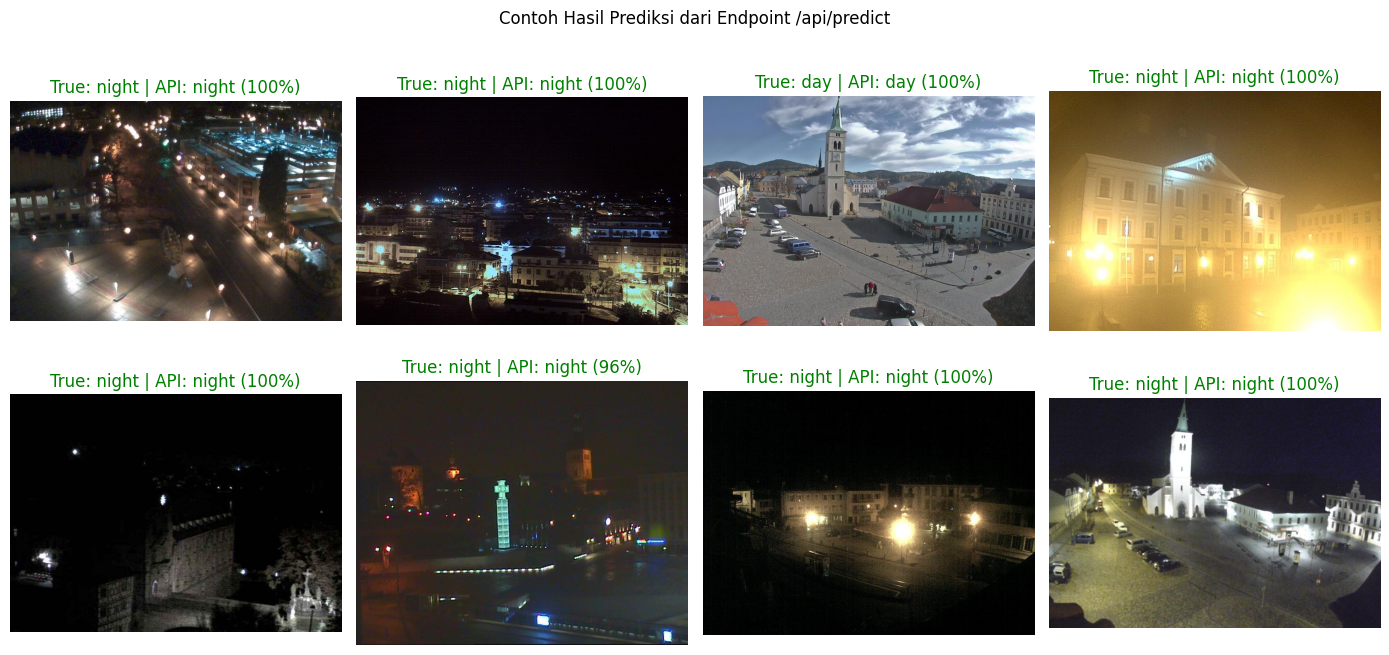

In [8]:
rng = np.random.default_rng(7)
pick = rng.choice(len(rows), 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, pick):
    path, t, p, conf = rows[i]
    ax.imshow(Image.open(path))
    ax.set_title(f"True: {t} | API: {p} ({conf*100:.0f}%)", color='green' if t == p else 'red')
    ax.axis('off')
plt.suptitle('Contoh Hasil Prediksi dari Endpoint /api/predict')
plt.tight_layout(); plt.show()

### Pengujian Docker Image Secara Lokal
Image juga dibangun dan dijalankan dengan Docker Desktop untuk memastikan container berjalan sebelum di-*push* (Hugging Face menjalankan proses build yang sama):

```bash
cd daynight-project
docker build -t daynight-classifier .
docker run --rm -p 7860:7860 daynight-classifier
# terminal lain:
curl -F "file=@../images/test/night/<nama_file>.jpg" http://localhost:7860/api/predict
```

**Hasil pengujian lokal:** image berhasil dibangun (ukuran ±3,2 GB, didominasi TensorFlow), container menampilkan log `System Loaded Successfully` dan `Running on http://0.0.0.0:7860`, kemudian request `curl` menghasilkan:

```json
night: {"class":"night","confidence":1.0,"label":"Night (Malam)","prob_day":0.0}
day:   {"class":"day","confidence":1.0,"label":"Day (Siang)","prob_day":1.0}
```

### Langkah 5 - Setup Hugging Face Space
1. Login ke [huggingface.co](https://huggingface.co) → foto profil → **New Space**.
2. Konfigurasi:
   * **Space name**: `daynight-classifier-254107023005`
   * **License**: MIT
   * **Space SDK**: **Docker** (template: *Blank*)
   * **Visibility**: Public
3. Klik **Create Space**.
4. Buat token: **Settings → Access Tokens → Create new token**, permission **Write**. Simpan token sementara (jangan di-*commit* ke repository mana pun).

### Langkah 6 - Upload ke Cloud dengan Git CLI
File model berukuran 17,8 MB, sedangkan Hugging Face menolak file biner tanpa **Git LFS/Xet**. Repository Space bawaan sudah memiliki `.gitattributes` yang men-*track* `*.h5` dan `*.pkl` dengan LFS, jadi cukup pastikan Git LFS aktif sebelum *clone*.

```bash
git lfs install

# 1. Clone repository Space (ganti USERNAME_HF)
git clone https://huggingface.co/spaces/USERNAME_HF/daynight-classifier-254107023005
cd daynight-classifier-254107023005

# 2. Salin file proyek ke folder hasil clone
cp ../daynight-project/{app.py,requirements.txt,Dockerfile,README.md,day_night_model.h5,scaler.pkl} .

# 3. Commit & push
git add .
git commit -m "Deploy aplikasi ke HF"
git push
```

Saat `git push`, isi **Username** dengan username Hugging Face dan **Password** dengan **Access Token** (bukan password akun).

### Langkah 7 - Pengujian dan Hasil Akhir
Setelah *push* selesai, buka tab **App** pada Space. Status berubah dari **Building** (biru) menjadi **Running** (hijau) dalam ±3–5 menit. Aplikasi dapat diakses di:

`https://USERNAME_HF-daynight-classifier-254107023005.hf.space`

> **Kendala deployment ke Hugging Face:** saat Space dibuat, Hugging Face menolak dengan pesan *"Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription"*. Docker Space kini hanya tersedia untuk akun **PRO**, sehingga deployment dilakukan sampai tahap **container Docker yang dijalankan secara lokal**. Image Docker yang sama persis inilah yang akan dibangun Hugging Face, jadi langkah 5–6 di atas tetap berlaku begitu akun PRO tersedia.

### Hasil Akhir: Aplikasi Berjalan di Container Docker
Container dijalankan dengan `docker run -d --name daynight-app -p 7860:7860 daynight-classifier` dan diakses melalui `http://localhost:7860`. Screenshot berikut adalah halaman yang dikirim langsung oleh container setelah gambar test diupload.

**Halaman utama**

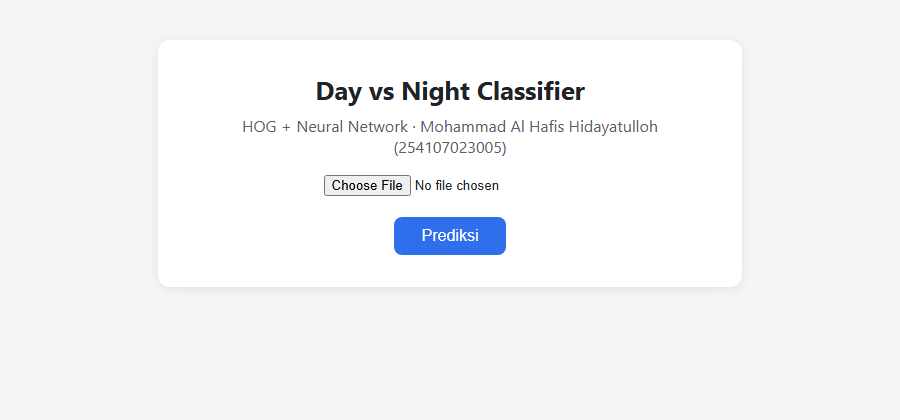

**Hasil prediksi citra siang**

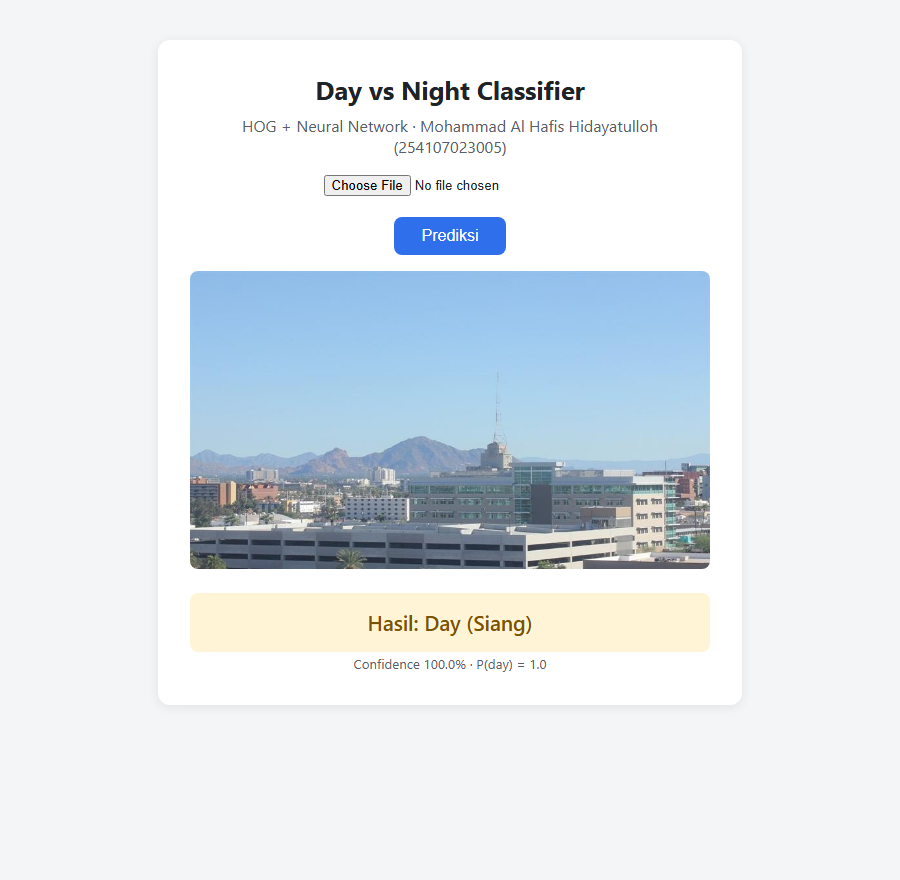

**Hasil prediksi citra malam**

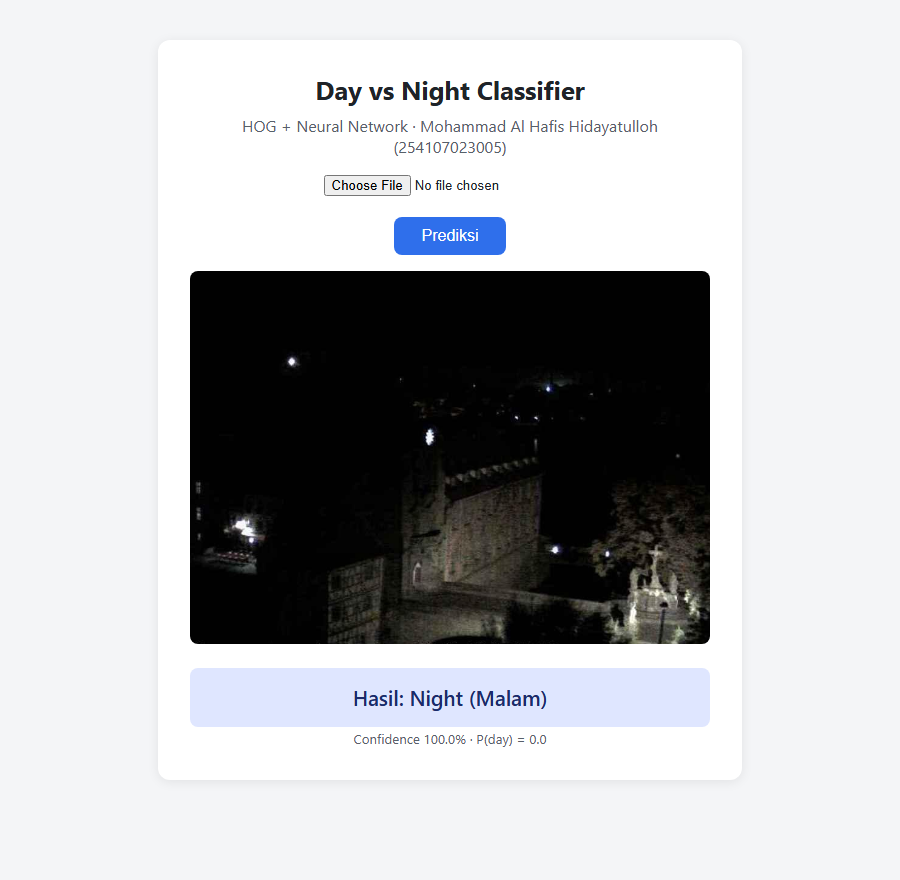

### Kesimpulan
1. Model dan scaler hasil training berhasil dibungkus menjadi web service Flask dengan dua antarmuka: halaman HTML untuk pengguna dan endpoint JSON `/api/predict` untuk integrasi aplikasi lain.
2. Pengujian 160 gambar test melalui API menghasilkan akurasi yang **sama** dengan evaluasi di Praktikum 1, membuktikan bahwa *pipeline* inferensi (resize → grayscale → HOG → scaler → model) identik dengan *pipeline* training. Konsistensi ini hanya mungkin karena parameter normalisasi disimpan di `scaler.pkl`.
3. *Pinning* versi library di `requirements.txt` dan *base image* Docker yang tetap menjamin lingkungan server sama dengan lingkungan training, sehingga menghindari masalah *dependency hell*.
4. Dengan Docker, aplikasi yang sudah berjalan di laptop dapat dijalankan dengan perilaku sama di Hugging Face Spaces maupun layanan cloud lain (Cloud Run, AWS ECS).
5. Deployment publik ke Hugging Face Spaces terkendala kebijakan baru yang mewajibkan langganan PRO untuk Docker Space. Aplikasi telah dibuktikan berjalan di container Docker lokal, dan file proyek siap di-*push* tanpa perubahan apa pun begitu akun PRO tersedia.